# Exploración de series de tiempo por municipio

Lee `Datos/datos_procesados/base_limpia.csv` (con la columna `AELEC`, el año de la elección) y explora cómo evoluciona la abstención de 2009 a 2024:
- Cómo se mueve la abstención nacional y por grupos (estado, sexo, edad, tipo de sección).
- Si un municipio con mucha abstención en una elección la repite en la siguiente (**persistencia**).
- Cuánto cambia la abstención de un municipio de una elección a otra (**volatilidad** y **cambio entre elecciones del mismo tipo**).
- Qué municipios tienen pocas elecciones o muy pocas personas (**cobertura y tamaño**).

La abstención se calcula **después de sumar** (`NV / (SV + NV)`), nunca promediando tasas. `NS` queda fuera.

## 1. Configuración y lectura

In [50]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

_cwd = Path.cwd().resolve()
RAIZ = next(p for p in [_cwd, *_cwd.parents] if (p / "Datos").is_dir())
RUTA_BASE = RAIZ / "Datos" / "datos_procesados" / "base_limpia.csv"

base = pd.read_csv(RUTA_BASE, encoding="utf-8-sig")
print(f"{len(base):,} filas")
base.head()

540,024 filas


,AELEC,FELECCION,TIPO_ELECCION,ESTADO,MUNICIPIO,SEXO,RANGO_EDAD,TIPOSEC,SV,NV,NS,ABSTENCION,CALIDAD_NS
0,2009,05/07/2009,Intermedia,AGUASCALIENTES,AGUASCALIENTES,Hombre,18-29,Mixto,765,2544,3512,0.7688,0.5149
1,2009,05/07/2009,Intermedia,AGUASCALIENTES,AGUASCALIENTES,Hombre,18-29,Rural,1002,2982,0,0.7485,0.0000
2,2009,05/07/2009,Intermedia,AGUASCALIENTES,AGUASCALIENTES,Hombre,18-29,Urbano,17777,45137,9191,0.7174,0.1275
3,2009,05/07/2009,Intermedia,AGUASCALIENTES,AGUASCALIENTES,Hombre,30-39,Mixto,723,1580,2814,0.6861,0.5499
4,2009,05/07/2009,Intermedia,AGUASCALIENTES,AGUASCALIENTES,Hombre,30-39,Rural,1067,2074,0,0.6603,0.0000


## 2. Tabla municipio × elección
Se suman SV, NV y NS de todas las filas de cada municipio en cada elección y se calcula la abstención municipal.

In [51]:
mun = base.groupby(["ESTADO", "MUNICIPIO", "AELEC", "TIPO_ELECCION"], as_index=False)[["SV", "NV", "NS"]].sum()
mun["PERSONAS"] = mun["SV"] + mun["NV"] + mun["NS"]
mun["ABSTENCION"] = mun["NV"] / (mun["SV"] + mun["NV"])
print(f"{len(mun):,} filas (municipio × elección)")
mun.head()

14,695 filas (municipio × elección)


,ESTADO,MUNICIPIO,AELEC,TIPO_ELECCION,SV,NV,NS,PERSONAS,ABSTENCION
0,AGUASCALIENTES,AGUASCALIENTES,2009,Intermedia,191384,264795,77338,533517,0.580463
1,AGUASCALIENTES,AGUASCALIENTES,2012,Presidencial,315393,216779,28,532200,0.407348
2,AGUASCALIENTES,AGUASCALIENTES,2015,Intermedia,197425,355774,36289,589488,0.643121
3,AGUASCALIENTES,AGUASCALIENTES,2018,Presidencial,366305,262151,8512,636968,0.417135
4,AGUASCALIENTES,AGUASCALIENTES,2021,Intermedia,305365,354541,22736,682642,0.537260


## 3. ¿Hay municipios sin registros?


In [52]:
mun.isna().sum()

ESTADO           0
MUNICIPIO        0
AELEC            0
TIPO_ELECCION    0
SV               0
NV               0
NS               0
PERSONAS         0
ABSTENCION       0
dtype: int64

## 4. Abstención nacional por elección
Abstención nacional = suma de NV entre suma de SV + NV. Se compara con cómo se reparte entre municipios (mínimo, cuartiles, máximo).

In [53]:
por_anio = mun.groupby("AELEC")[["SV", "NV"]].sum()
nacional = por_anio["NV"] / (por_anio["SV"] + por_anio["NV"])
resumen = mun.groupby("AELEC")["ABSTENCION"].describe()[["count", "min", "25%", "50%", "75%", "max"]]
resumen.insert(0, "nacional", nacional)
resumen.round(3)

,nacional,count,min,25%,50%,75%,max
AELEC,,,,,,,
2009,0.559,2449.0,0.138,0.437,0.547,0.630,0.911
2012,0.379,2452.0,0.050,0.300,0.360,0.421,1.000
2015,0.529,2427.0,0.045,0.362,0.492,0.581,0.986
2018,0.376,2448.0,0.043,0.263,0.334,0.399,0.742
2021,0.482,2456.0,0.056,0.284,0.386,0.497,0.921
2024,0.403,2463.0,0.055,0.299,0.377,0.448,0.803


## 5. Serie nacional
Abstención nacional de cada elección. Azul = presidencial (2012, 2018, 2024), naranja = intermedia (2009, 2015, 2021). 2027 será intermedia.

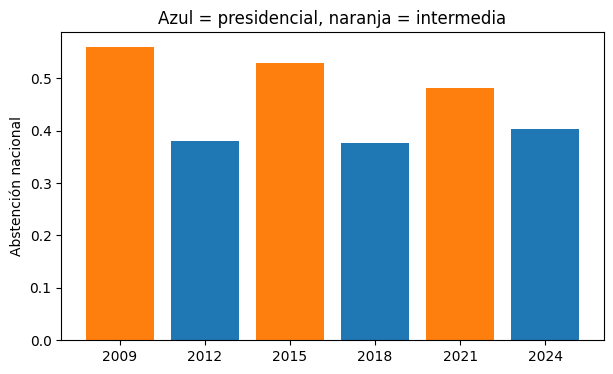

In [54]:
tipo_anio = mun.groupby("AELEC")["TIPO_ELECCION"].first()
colores = tipo_anio.map({"Presidencial": "tab:blue", "Intermedia": "tab:orange"})
plt.figure(figsize=(7, 4))
plt.bar(nacional.index.astype(str), nacional.values, color=colores.values)
plt.ylabel("Abstención nacional")
plt.title("Azul = presidencial, naranja = intermedia")
plt.show()


## 6. Series por estado
Abstención de cada estado por elección (líneas grises) contra el nivel nacional (línea roja). Muestra si los estados se mueven juntos o cada uno va por su cuenta.

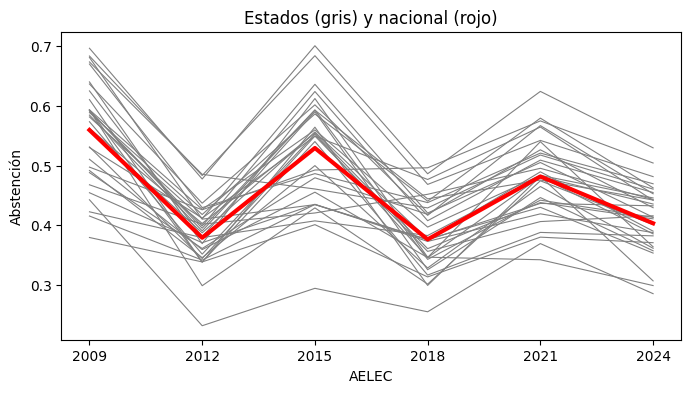

Estados con más abstención en 2024:
ESTADO
BAJA CALIFORNIA        0.530
SONORA                 0.504
CHIHUAHUA              0.481
BAJA CALIFORNIA SUR    0.469
DURANGO                0.463
Name: 2024, dtype: float64

Estados con menos abstención en 2024:
ESTADO
YUCATAN             0.286
TLAXCALA            0.299
CIUDAD DE MEXICO    0.307
COAHUILA            0.353
PUEBLA              0.357
Name: 2024, dtype: float64


In [55]:
est = mun.groupby(["AELEC", "ESTADO"])[["SV", "NV"]].sum()
est["ABSTENCION"] = est["NV"] / (est["SV"] + est["NV"])
est_ancho = est["ABSTENCION"].unstack()

est_ancho.plot(legend=False, color="gray", linewidth=0.8, figsize=(8, 4), xticks=est_ancho.index)
nacional.plot(color="red", linewidth=3)
plt.ylabel("Abstención")
plt.title("Estados (gris) y nacional (rojo)")
plt.show()
print("Estados con más abstención en 2024:")
print(est_ancho.loc[2024].sort_values(ascending=False).head(5).round(3))
print("\nEstados con menos abstención en 2024:")
print(est_ancho.loc[2024].sort_values().head(5).round(3))

## 7. Series por sexo, edad y tipo de sección
La misma serie nacional, separada por grupos. Responde si el patrón de abstención cambia según quién es la persona y dónde vive.

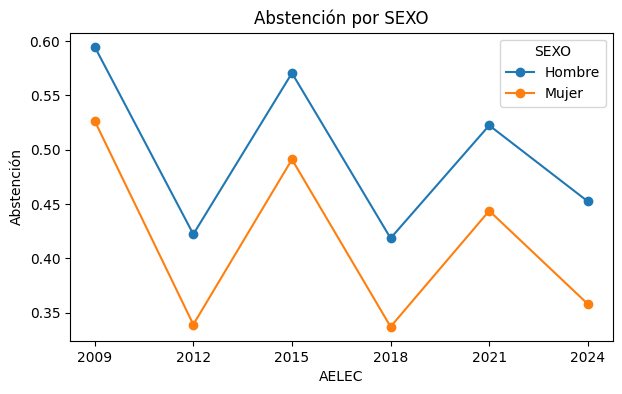

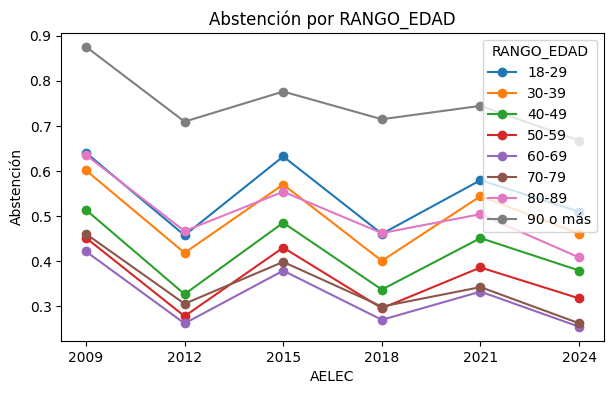

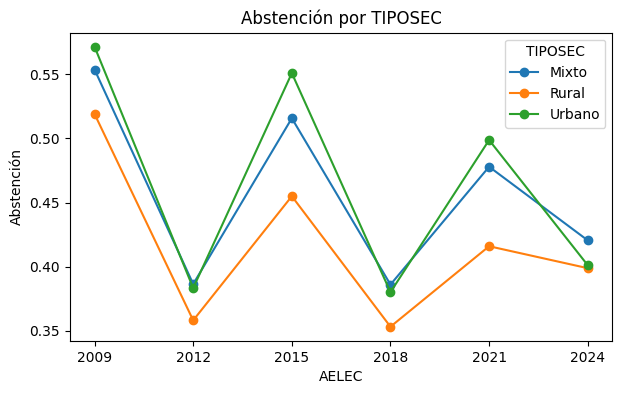

In [56]:
for columna in ["SEXO", "RANGO_EDAD", "TIPOSEC"]:
    t = base.groupby(["AELEC", columna])[["SV", "NV"]].sum()
    t["ABSTENCION"] = t["NV"] / (t["SV"] + t["NV"])
    t["ABSTENCION"].unstack().plot(marker="o", figsize=(7, 4), xticks=nacional.index, title=f"Abstención por {columna}")
    plt.ylabel("Abstención")
    plt.show()

## 8. Abstención de cada municipio en cada elección (tabla ancha)
Una fila por municipio y una columna por año. Los municipios que no existían en un año quedan vacíos.

In [57]:
ancha = mun.pivot_table(index=["ESTADO", "MUNICIPIO"], columns="AELEC", values="ABSTENCION")
print(ancha.shape)
ancha.head()

(2475, 6)


AELEC                              2009      2012      2015      2018  \
ESTADO         MUNICIPIO                                                
AGUASCALIENTES AGUASCALIENTES  0.580463  0.407348  0.643121  0.417135   
               ASIENTOS        0.571159  0.394725  0.527214  0.359880   
               CALVILLO        0.651466  0.468959  0.645070  0.486471   
               COSIO           0.501740  0.388039  0.601035  0.437801   
               EL LLANO        0.519156  0.384958  0.561265  0.406381   

AELEC                              2021      2024  
ESTADO         MUNICIPIO                           
AGUASCALIENTES AGUASCALIENTES  0.537260  0.419166  
               ASIENTOS        0.344491  0.357233  
               CALVILLO        0.498826  0.481621  
               COSIO           0.233295  0.277838  
               EL LLANO        0.309673  0.323002

## 9. Persistencia: correlación entre elecciones
Correlación entre la abstención de los municipios en dos elecciones. Cerca de 1 = los municipios con mucha abstención en una elección la repiten en la otra.

In [58]:
corr = ancha.corr()
corr.round(2)

AELEC,2009,2012,2015,2018,2021,2024
AELEC,,,,,,
2009,1.00,0.72,0.67,0.47,0.48,0.45
2012,0.72,1.00,0.66,0.74,0.68,0.69
2015,0.67,0.66,1.00,0.57,0.54,0.52
2018,0.47,0.74,0.57,1.00,0.85,0.85
2021,0.48,0.68,0.54,0.85,1.00,0.82
2024,0.45,0.69,0.52,0.85,0.82,1.00


## 10. Persistencia: elecciones consecutivas y del mismo tipo
Se separa la correlación entre elecciones seguidas (p. ej. 2018 y 2021) de la correlación entre elecciones del mismo tipo (intermedia con intermedia). La que importa para 2027 es la segunda.

In [59]:
anios = [2009, 2012, 2015, 2018, 2021, 2024]
print("Consecutivas:")
for a, b in zip(anios[:-1], anios[1:]):
    print(f"  {a} y {b}: {ancha[a].corr(ancha[b]):.3f}")
print("Mismo tipo:")
for a, b in [(2009, 2015), (2015, 2021), (2012, 2018), (2018, 2024)]:
    print(f"  {a} y {b}: {ancha[a].corr(ancha[b]):.3f}")

Consecutivas:
  2009 y 2012: 0.723
  2012 y 2015: 0.657
  2015 y 2018: 0.570
  2018 y 2021: 0.848
  2021 y 2024: 0.816
Mismo tipo:
  2009 y 2015: 0.671
  2015 y 2021: 0.544
  2012 y 2018: 0.737
  2018 y 2024: 0.847


## 11. Gráficas de persistencia
Cada punto es un municipio. Arriba se comparan las elecciones **intermedias** entre sí (2009 con 2015, 2015 con 2021) y abajo las **presidenciales** (2012 con 2018, 2018 con 2024). Nunca se mezclan los tipos, porque cada tipo tiene su propio nivel de abstención. Si los puntos siguen la diagonal roja, la abstención pasada predice la futura; mientras más dispersos, menos se parece una elección a la otra.

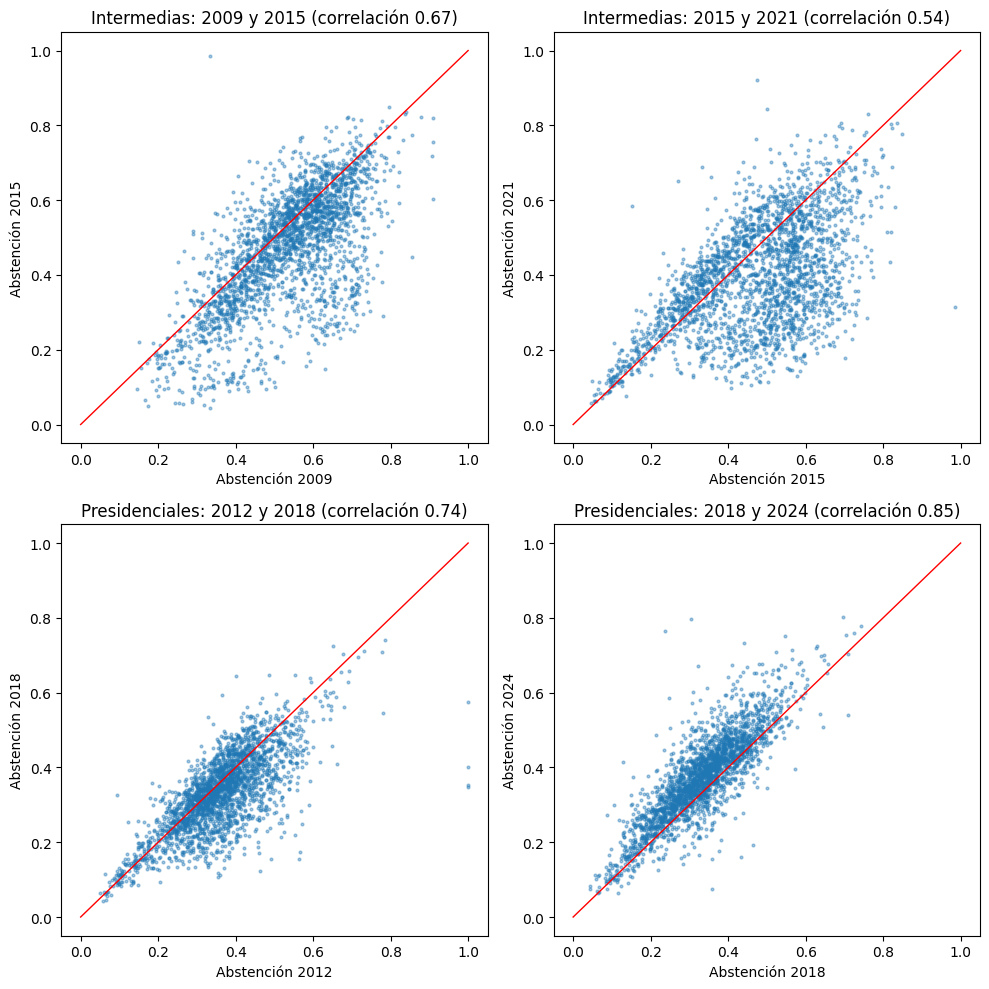

In [60]:
fig, ejes = plt.subplots(2, 2, figsize=(10, 10))
pares = [[(2009, 2015), (2015, 2021)], [(2012, 2018), (2018, 2024)]]
tipos = ["Intermedias", "Presidenciales"]

for fila, tipo in zip(range(2), tipos):
    for col in range(2):
        a, b = pares[fila][col]
        eje = ejes[fila, col]
        eje.scatter(ancha[a], ancha[b], s=4, alpha=0.4)
        eje.plot([0, 1], [0, 1], color="red", linewidth=1)
        eje.set_xlabel(f"Abstención {a}")
        eje.set_ylabel(f"Abstención {b}")
        eje.set_title(f"{tipo}: {a} y {b} (correlación {ancha[a].corr(ancha[b]):.2f})")

plt.tight_layout()
plt.show()


## 12. Volatilidad
Cada elección tiene su nivel nacional (las presidenciales tienen menos abstención). Para no confundir eso con volatilidad del municipio, se calcula la **diferencia** = abstención del municipio − abstención nacional del año. La volatilidad es la desviación estándar de esa diferencia en las elecciones del municipio.

count    2465.000
mean        0.076
std         0.033
min         0.012
25%         0.053
50%         0.072
75%         0.093
max         0.289
Name: VOLATILIDAD, dtype: float64


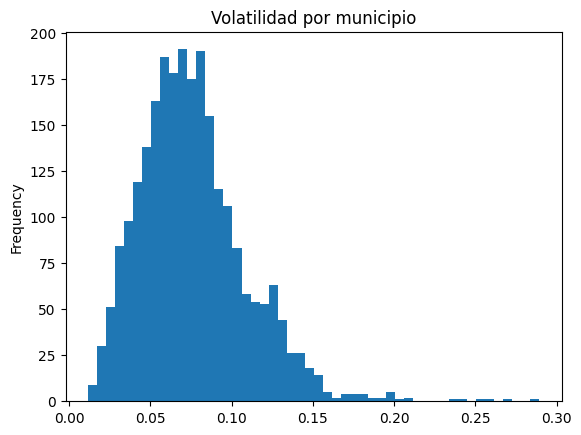

In [61]:
mun["DIFERENCIA"] = mun["ABSTENCION"] - mun["AELEC"].map(nacional)
vol = mun.groupby(["ESTADO", "MUNICIPIO"])["DIFERENCIA"].agg(["count", "mean", "std"])
vol.columns = ["ELECCIONES", "DIFERENCIA_MEDIA", "VOLATILIDAD"]
print(vol["VOLATILIDAD"].describe().round(3))
vol["VOLATILIDAD"].plot.hist(bins=50, title="Volatilidad por municipio")
plt.show()

## 13. Tamaño de los municipios
Personas en la lista (`SV + NV + NS`) de cada municipio, promedio de sus elecciones. En municipios chicos la tasa se mueve más por azar.

In [62]:
vol["PERSONAS"] = mun.groupby(["ESTADO", "MUNICIPIO"])["PERSONAS"].mean()
print(vol["PERSONAS"].describe().round(0))

cortes = [0, 500, 1000, 5000, 10000, 50000, float("inf")]
nombres = ["< 500", "500-1,000", "1,000-5,000", "5,000-10,000", "10,000-50,000", "> 50,000"]
vol["TAMANIO"] = pd.cut(vol["PERSONAS"], cortes, labels=nombres, right=False)

tamaños = vol.groupby("TAMANIO", observed=True).agg(municipios=("PERSONAS", "size"), personas=("PERSONAS", "sum"))
tamaños["pct_municipios"] = (tamaños["municipios"] / tamaños["municipios"].sum() * 100).round(1)
tamaños["pct_personas"] = (tamaños["personas"] / tamaños["personas"].sum() * 100).round(1)
tamaños

count       2475.0
mean       34987.0
std       104824.0
min           70.0
25%         3308.0
50%         9446.0
75%        23750.0
max      1441826.0
Name: PERSONAS, dtype: float64


,municipios,personas,pct_municipios,pct_personas
TAMANIO,,,,
< 500,63,2.075283e+04,2.5,0.0
"500-1,000",108,7.953700e+04,4.4,0.1
"1,000-5,000",682,1.905689e+06,27.6,2.2
"5,000-10,000",423,3.109454e+06,17.1,3.6
"10,000-50,000",889,1.937435e+07,35.9,22.4
"> 50,000",310,6.210287e+07,12.5,71.7


## 14. ¿Los municipios chicos son más volátiles?
Volatilidad promedio por grupo de tamaño. Si baja al crecer el municipio, parte de la volatilidad es ruido por pocos habitantes.

In [63]:
vol.groupby("TAMANIO", observed=True)["VOLATILIDAD"].agg(["count", "mean", "median"]).round(3)

,count,mean,median
TAMANIO,,,
< 500,63,0.070,0.057
"500-1,000",108,0.077,0.066
"1,000-5,000",681,0.084,0.080
"5,000-10,000",418,0.088,0.083
"10,000-50,000",886,0.073,0.071
"> 50,000",309,0.052,0.050


## 15. Cambio entre elecciones del mismo tipo
Cuánto cambió la abstención de cada municipio entre dos intermedias (2015 → 2021) y entre dos presidenciales (2018 → 2024). También se mide el error que se comete si se supone que cada municipio cambia igual que el país: es el punto de comparación que un modelo debe mejorar.

2015 -> 2021 | cambio nacional: -0.048
  cambio por municipio: media -0.077, desviación 0.143
  error promedio si cada municipio cambiara igual que el país: 0.118
  correlación entre el cambio y la abstención inicial: -0.521
2018 -> 2024 | cambio nacional: +0.027
  cambio por municipio: media +0.043, desviación 0.061
  error promedio si cada municipio cambiara igual que el país: 0.045
  correlación entre el cambio y la abstención inicial: -0.101


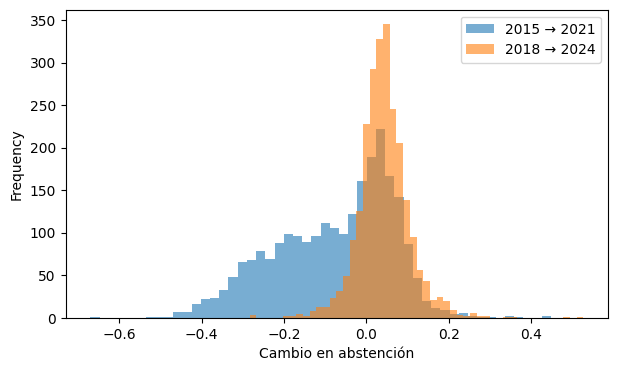

In [65]:
for a, b in [(2015, 2021), (2018, 2024)]:
    cambio = ancha[b] - ancha[a]
    cambio_nac = nacional[b] - nacional[a]
    print(f"{a} -> {b} | cambio nacional: {cambio_nac:+.3f}")
    print(f"  cambio por municipio: media {cambio.mean():+.3f}, desviación {cambio.std():.3f}")
    print(f"  error promedio si cada municipio cambiara igual que el país: {(cambio - cambio_nac).abs().mean():.3f}")
    print(f"  correlación entre el cambio y la abstención inicial: {cambio.corr(ancha[a]):.3f}")

plt.figure(figsize=(7, 4))
(ancha[2021] - ancha[2015]).plot.hist(bins=50, alpha=0.6, label="2015 → 2021")
(ancha[2024] - ancha[2018]).plot.hist(bins=50, alpha=0.6, label="2018 → 2024")
plt.xlabel("Cambio en abstención")
plt.legend()
plt.show()

## 16. Cobertura: cuántas elecciones tiene cada municipio
Municipios por número de elecciones y el porcentaje de la lista nominal de 2024 que representan.

In [66]:
pers_2024 = mun[mun["AELEC"] == 2024].set_index(["ESTADO", "MUNICIPIO"])["PERSONAS"]
vol["PERSONAS_2024"] = pers_2024
cobertura = vol.groupby("ELECCIONES").agg(municipios=("ELECCIONES", "size"), personas_2024=("PERSONAS_2024", "sum"))
cobertura["pct_personas_2024"] = (cobertura["personas_2024"] / pers_2024.sum() * 100).round(2)
cobertura

,municipios,personas_2024,pct_personas_2024
ELECCIONES,,,
1,10,202026.0,0.21
2,4,52180.0,0.05
3,5,47582.0,0.05
4,2,6210.0,0.01
5,70,362141.0,0.37
6,2384,97556968.0,99.32


## 17. Municipios con pocas elecciones
Los que tienen menos de 6 elecciones (nuevos o con cambios), con su tamaño en 2024. Los que salen vacíos no tienen dato en 2024.

In [69]:
pd.set_option("display.max_rows", None)

pocas = vol[vol["ELECCIONES"] < 6].sort_values("ELECCIONES", kind="stable")
pocas[["ELECCIONES", "PERSONAS_2024"]].join(ancha.round(3))

ELECCIONES  \
ESTADO          MUNICIPIO                                          
BAJA CALIFORNIA SAN FELIPE                                     1   
                SAN QUINTIN                                    1   
CHIAPAS         HONDURAS DE LA SIERRA                          1   
GUERRERO        LAS VIGAS                                      1   
                NUU SAVI                                       1   
                SAN NICOLAS                                    1   
                SANTA CRUZ DEL RINCON                          1   
MORELOS         HUEYAPAN                                       1   
SINALOA         ELDORADO                                       1   
                JUAN JOSE RIOS                                 1   
CAMPECHE        DZITBALCHE                                     2   
                SEYBAPLAYA                                     2   
MORELOS         COATETELCO                                     2   
                XOXOCOTLA                                      2   
CHIAPAS         CAPITAN LUIS ANGEL VIDAL                       3   
                EL PARRAL                                      3   
                EMILIANO ZAPATA                                3   
                MEZCALAPA                                      3   
                RINCON CHAMULA SAN PEDRO                       3   
OAXACA          SAN MATEO DEL MAR                              4   
                SANTA ANA TAVELA                               4   
CHIAPAS         CHICOMUSELO                                    5   
                METAPA                                         5   
                OXCHUC                                         5   
                PANTELHO                                       5   
                SAN ANDRES DURAZNAL                            5   
                SILTEPEC                                       5   
                SOYALO                                         5   
                VENUSTIANO CARRANZA                            5   
CHIHUAHUA       ROSALES                                        5   
GUANAJUATO      MANUEL DOBLADO                                 5   
HIDALGO         AGUA BLANCA DE ITURBIDE                        5   
                HUEHUETLA                                      5   
                SAN BARTOLO TUTOTEPEC                          5   
                SANTIAGO TULANTEPEC DE LUGO GUERRERO           5   
MICHOACAN       ZIRACUARETIRO                                  5   
NUEVO LEON      HIGUERAS                                       5   
                ITURBIDE                                       5   
                RAYONES                                        5   
OAXACA          CAPULALPAM DE MENDEZ                           5   
                CHAHUITES                                      5   
                ELOXOCHITLAN DE FLORES MAGON                   5   
                HUAUTEPEC                                      5   
                LA REFORMA                                     5   
                MAGDALENA MIXTEPEC                             5   
                MAGDALENA OCOTLAN                              5   
                MAZATLAN VILLA DE FLORES                       5   
                REFORMA DE PINEDA                              5   
                SAN BALTAZAR CHICHICAPAM                       5   
                SAN DIONISIO DEL MAR                           5   
                SAN DIONISIO OCOTLAN                           5   
                SAN FRANCISCO CAJONOS                          5   
                SAN FRANCISCO DEL MAR                          5   
                SAN FRANCISCO HUEHUETLAN                       5   
                SAN FRANCISCO IXHUATAN                         5   
                SAN FRANCISCO LACHIGOLO                        5   
                SAN FRANCISCO NUXANO                           5   
                SAN JERONIMO TECOATL      

## 18. ¿Cuánto cambia el orden de los municipios entre elecciones?
Cada elección se divide en cuatro grupos del mismo tamaño según la abstención de los municipios: el grupo 1 es la cuarta parte con menos abstención y el grupo 4 la cuarta parte con más. Después se ve, para cada par de elecciones, qué porcentaje de los municipios **se queda en su mismo grupo** (la diagonal de la tabla de cambio de grupo). Con 4 grupos, 25 % es lo que pasaría al azar: mientras más arriba de 25 %, más se conserva el orden y más sirve un semáforo hecho con una elección para la siguiente.


In [75]:
anios = [2009, 2012, 2015, 2018, 2021, 2024]
grupos = ["1 baja", "2", "3", "4 alta"]

filas = []
for i, a in enumerate(anios):
    for b in anios[i + 1:]:
        t = ancha[[a, b]].dropna().copy()
        t["Qa"] = pd.qcut(t[a], 4, labels=grupos)
        t["Qb"] = pd.qcut(t[b], 4, labels=grupos)
        tabla = pd.crosstab(t["Qa"], t["Qb"], normalize="index") * 100
        filas.append([f"{a} → {b}"] + [tabla.iloc[k, k] for k in range(4)])

resumen = pd.DataFrame(filas, columns=["Comparación", "1 baja", "2", "3", "4 alta"])
resumen.round(1)


,Comparación,1 baja,2,3,4 alta
0,2009 → 2012,65.7,36.2,39.3,64.5
1,2009 → 2015,66.1,39.8,37.2,53.6
2,2009 → 2018,46.0,24.5,31.2,44.3
3,2009 → 2021,45.9,19.3,27.9,42.6
4,2009 → 2024,43.6,22.2,28.2,43.7
5,2012 → 2015,65.5,32.0,35.7,50.0
6,2012 → 2018,64.9,41.6,40.2,62.1
7,2012 → 2021,63.8,37.0,33.9,55.8
8,2012 → 2024,58.0,35.4,34.3,58.4
9,2015 → 2018,53.8,25.5,29.9,44.7
